# **PONTIFICIA UNIVERSIDAD JAVERIANA**
<img src="https://www.javeriana.edu.co/recursosdb/8091523/8157776/javeriana-web-logo-edu.png/d5eb5e3d-2e95-0d4f-877d-0ed67a254251?t=1676557813805" width="30%" alt="Logo de la Pontificia Universidad Javeriana">

## Alisson Garcia Salazar
## ID: 20528254
## Clase: Procesamiento de Datos a Gran Escala

**Fecha**: 24 de Noviembre 2026

**Taller**: Clasificación de ingresos anuales con PySpark MLlib

## 1. Contexto y objetivos

Adult (Census Income) es un conjunto de datos históricos del censo de Estados Unidos. 
El problema es de clasificación binaria. La clase positiva representa ingresos anuales superiores a USD 50.000 y la negativa incluye ingresos iguales o inferiores a ese umbral.

**Objetivo general.** Entrenar y comparar cinco clasificadores de Spark MLlib para predecir si una persona supera USD 50.000 anuales.

**Objetivos específicos**

- Almacenar las particiones de UCI en HDFS y leerlas con Spark.
- Inspeccionar la distribución y preparar variables numéricas y categóricas.
- Evaluar los cinco clasificadores en la misma partición de prueba y compararlos con la clase mayoritaria.

**Fuente**  [UCI Machine Learning Repository Census Income](https://archive.ics.uci.edu/dataset/20/census+income)

## 2. Configuración de Spark y Hadoop

Se conserva el bloque de importaciones del taller de ICTUS y se agregan las dependencias de esta entrega. El puerto de la interfaz Spark se toma del taller anterior y puede ajustarse en la celda de configuración si el profesor asignó otro.

In [1]:
# Importa bibliotecas para esta etapa del taller.
#Librerías
import numpy as np # Operaciones numéricas y vectores
import pandas as pd # Manipulación de datos tabulares, CSV (ej. pd.read_csv)

#Librerías de Apache Spark
import findspark
findspark.init('/mnt/sda1/Cluster/Spark')
import pyspark #API de Spark para python
#Biblioteca para configuraciones y SESSION SPARK
from pyspark import SparkContext, SparkConf
from pyspark.sql import SparkSession, SQLContext # Punto de entrada para usar Spark SQL/DataFrames
from pyspark.sql import functions as F

In [2]:
# Importa bibliotecas para esta etapa del taller.
#Algoritmos de clasificación de Spark ML
from pyspark.ml.classification import DecisionTreeClassifier,RandomForestClassifier,NaiveBayes

#Evaluador de modelos multiclase
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

#Transformadores de features de Spark ML
from pyspark.ml.feature import StandardScaler,StringIndexer, VectorAssembler, VectorIndexer, OneHotEncoder

#Utilidad para encadenar etapas de ML
from pyspark.ml import Pipeline

In [3]:
# Importa bibliotecas para esta etapa del taller.
#Apache Spark `DenseVector` (necesario para crear la columna features)
from pyspark.ml.linalg import DenseVector

#Data Split Libraries
import sklearn
from sklearn.model_selection import train_test_split

#Recolector de basura (liberar memoria)
import gc

In [4]:
# Importa bibliotecas para esta etapa del taller.
### Bibliotecas adicionales

#Biblioteca para estadística/inferencia/probabilidades y pintar
import seaborn as sns
#Biblioteca para pintar
import matplotlib.pyplot as plt

In [5]:
# Importa utilidades de archivos, visualización y modelos adicionales.
from pathlib import Path
from subprocess import run
from IPython.display import display
from pyspark.ml.classification import LogisticRegression, GBTClassifier, LinearSVC
from pyspark.ml.evaluation import BinaryClassificationEvaluator

In [6]:
# Define el puerto de Spark y la ruta de HDFS.
PUERTO_SPARK_UI = "37008"
HADOOP = "/mnt/sda1/Cluster/Hadoop/bin/hadoop"
HDFS = "hdfs://10.195.34.34:9000"
CARPETA_HDFS = HDFS + "/Formatos1055/Garcia/CensusIncome"

In [7]:
# Inicia la sesión Spark del taller.
configura = SparkConf().set("spark.ui.port", PUERTO_SPARK_UI)
configura.setAppName("GarciaSalario_1055")
sparkGarcia = SparkSession.builder.config(conf=configura).getOrCreate()
sparkContextoGarcia = sparkGarcia.sparkContext
sqlContextoGarcia = SQLContext(sparkContext=sparkContextoGarcia, sparkSession=sparkGarcia)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


In [8]:
# Verifica la versión, la sesión y el puerto de Spark.
print("Spark:", sparkGarcia.version)
print("Sesión:", sparkContextoGarcia.appName)
print("Interfaz:", sparkContextoGarcia.uiWebUrl)

Spark: 3.5.5
Sesión: GarciaSalario_1055
Interfaz: http://clusterHPC:37008


### Carga de los archivos en HDFS

Los archivos descomprimidos se copian desde la carpeta del cuaderno a HDFS. La lectura y el procesamiento posteriores se hacen con Spark desde esa ubicación. Si vuelves a ejecutar la celda, se actualizan únicamente los dos archivos de datos en la carpeta de esta entrega.

In [9]:
# Comprueba que llegaron ambos archivos de UCI.
archivos = ("adult.data", "adult.test")
faltantes = [nombre for nombre in archivos if not Path(nombre).is_file()]
if faltantes:
    raise FileNotFoundError("Sube a la carpeta del cuaderno: " + ", ".join(faltantes))

In [10]:
# Ejecuta comandos del sistema de archivos de Hadoop.
def hadoop_fs(*argumentos):
    run([HADOOP, "fs", *argumentos], check=True)

In [11]:
# Crea la carpeta y copia los datos a HDFS.
hadoop_fs("-mkdir", "-p", CARPETA_HDFS)
for nombre in archivos:
    hadoop_fs("-put", "-f", nombre, f"{CARPETA_HDFS}/{nombre}")

In [12]:
# Confirma que los dos archivos quedaron en HDFS.
hadoop_fs("-ls", CARPETA_HDFS)

Found 2 items
-rw-r--r--   2 usuario08 supergroup    3974305 2026-11-24 11:59 hdfs://10.195.34.34:9000/Formatos1055/Garcia/CensusIncome/adult.data
-rw-r--r--   2 usuario08 supergroup    2003153 2026-11-24 11:59 hdfs://10.195.34.34:9000/Formatos1055/Garcia/CensusIncome/adult.test


## 3. Conocimiento de los datos

UCI entrega 32.561 filas para entrenamiento y 16.281 para prueba. Se conserva esa separación. Los archivos traen 14 variables predictoras y una etiqueta, sin encabezado. En prueba se omite la primera línea informativa, que empieza con `|`.

| Grupo | Variables |
|---|---|
| Numéricas | Edad, peso muestral, nivel educativo numérico, ganancias y pérdidas de capital, horas trabajadas por semana |
| Categóricas | Tipo de empleo, educación, estado civil, ocupación, relación familiar, raza, sexo y país de origen |
| Objetivo | Ingreso anual, categorizado como `<=50K` o `>50K` |

In [13]:
# Asigna los nombres a las columnas sin encabezado.
numericas = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
categoricas = ["workclass", "education", "marital_status", "occupation", "relationship",
               "race", "sex", "native_country"]
columnas = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]

In [14]:
# Lee desde HDFS y conserva la partición original.
def leer_adult(nombre):
    return (sparkGarcia.read.option("header", "false").option("comment", "|")
            .option("mode", "FAILFAST").csv(f"{CARPETA_HDFS}/{nombre}").toDF(*columnas))

adult_train = leer_adult("adult.data")
adult_test = leer_adult("adult.test")

In [15]:
# Revisa tamaños, etiquetas y faltantes por columna.
for conjunto, datos in [("Entrenamiento", adult_train), ("Prueba", adult_test)]:
    print(conjunto, datos.count())
    datos.groupBy(F.trim("income").alias("ingreso_original")).count().show()
    datos.select([
        F.sum(F.when(F.col(c).isNull() | (F.trim(c) == "?"), 1).otherwise(0)).alias(c)
        for c in columnas
    ]).show(truncate=False)
adult_train.show(5, truncate=False)

Entrenamiento 32561
+----------------+-----+
|ingreso_original|count|
+----------------+-----+
|           <=50K|24720|
|            >50K| 7841|
+----------------+-----+

+---+---------+------+---------+-------------+--------------+----------+------------+----+---+------------+------------+--------------+--------------+------+
|age|workclass|fnlwgt|education|education_num|marital_status|occupation|relationship|race|sex|capital_gain|capital_loss|hours_per_week|native_country|income|
+---+---------+------+---------+-------------+--------------+----------+------------+----+---+------------+------------+--------------+--------------+------+
|0  |1836     |0     |0        |0            |0             |1843      |0           |0   |0  |0           |0           |0             |583           |0     |
+---+---------+------+---------+-------------+--------------+----------+------------+----+---+------------+------------+--------------+--------------+------+

Prueba 16281
+----------------+-----+


### Tipos de faltantes antes de la limpieza

In [16]:
# Distingue nulos, cadenas vacías y marcadores '?' en las columnas de origen.
def tipos_faltantes(datos):
    expresiones = []
    for c in columnas:
        valor = F.trim(F.col(c))
        for tipo, condicion in [("Nulo", F.col(c).isNull()), ("Vacío", valor == ""), ("?", valor == "?")]:
            expresiones.append(F.count(F.when(condicion, 1)).alias(f"{c}|{tipo}"))
    conteos = datos.select(*expresiones).first().asDict()
    return [(clave.rsplit("|", 1)[0], clave.rsplit("|", 1)[1], total)
            for clave, total in conteos.items()]

In [17]:
# Presenta totales por tipo y detalle de las columnas afectadas.
perfil_faltantes = pd.DataFrame([
    (parte, columna, tipo, total)
    for parte, datos in [("Entrenamiento", adult_train), ("Prueba", adult_test)]
    for columna, tipo, total in tipos_faltantes(datos)
], columns=["Partición", "Variable", "Tipo", "Registros"])
display(perfil_faltantes.groupby(["Partición", "Tipo"])["Registros"].sum().unstack())
display(perfil_faltantes.loc[perfil_faltantes["Registros"] > 0])

26/11/24 11:59:14 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Tipo,?,Nulo,Vacío
Partición,,,
Entrenamiento,4262,0,0
Prueba,2203,0,0


,Partición,Variable,Tipo,Registros
5,Entrenamiento,workclass,?,1836
20,Entrenamiento,occupation,?,1843
41,Entrenamiento,native_country,?,583
50,Prueba,workclass,?,963
65,Prueba,occupation,?,966
86,Prueba,native_country,?,274


El diagnóstico distingue los tres tipos de faltante. Los marcadores `?` suman 4.262 celdas en entrenamiento y 2.203 en prueba, concentradas en ocupación, tipo de empleo y país de origen. Estos totales cuentan celdas y una persona puede tener más de un campo faltante.

### Diagnóstico gráfico de faltantes

In [18]:
# Cuenta nulos y marcadores de faltantes por columna.
def contar_faltantes(datos):
    expresiones = [F.sum(F.when(F.col(c).isNull() | F.trim(c).isin("?", ""), 1)
                         .otherwise(0)).alias(c) for c in columnas]
    return datos.select(*expresiones).first().asDict()

faltantes_grafico = pd.DataFrame({
    "Entrenamiento": contar_faltantes(adult_train),
    "Prueba": contar_faltantes(adult_test)
})
faltantes_grafico = faltantes_grafico.loc[faltantes_grafico.sum(axis=1) > 0]

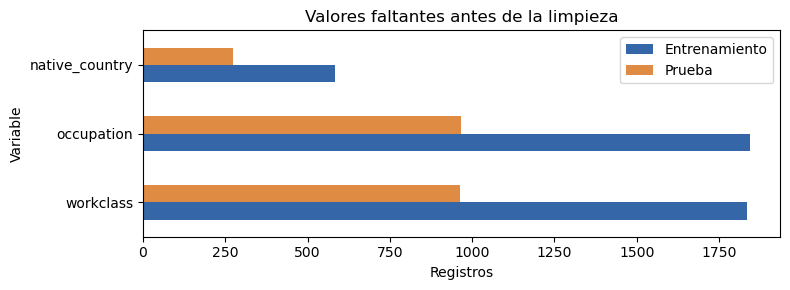

In [19]:
# Grafica los faltantes por columna y partición.
ax = faltantes_grafico.plot.barh(figsize=(8, 3), color=["#3567A8", "#E08B43"])
ax.set(title="Valores faltantes antes de la limpieza", xlabel="Registros", ylabel="Variable")
plt.tight_layout()
plt.show()

Los faltantes se concentraron en ocupación (1.843 en entrenamiento y 966 en prueba), tipo de empleo (1.836 y 963) y país de origen (583 y 274). En los archivos originales aparecen como `?`. El recuento también contempla nulos y cadenas vacías. Se usó la categoría `Desconocido` para conservar los registros.

## 4. Preparación de los datos

Se eliminan espacios y el punto final de la etiqueta de prueba. La clase positiva queda como `1.0`. Para preservar las filas, los faltantes categóricos se conservan bajo la categoría `Desconocido`. Se verifica la validez de las etiquetas y de las variables numéricas antes de entrenar.

Se omite `fnlwgt` como predictor porque es un peso muestral. Se conserva `education_num` y se omite `education` para evitar incluir dos representaciones del mismo atributo. Se incluyen los demás atributos del ejercicio, incluidos atributos demográficos. Esta inclusión exige cautela al interpretar los resultados y no permite afirmar equidad entre grupos.

In [20]:
# Limpia categorías y convierte ingresos en una etiqueta binaria.
def preparar(datos):
    ingreso = F.regexp_replace(F.trim("income"), r"\.$", "")
    return datos.select(
        *[F.trim(c).cast("double").alias(c) for c in numericas],
        *[F.when(F.col(c).isNull() | F.trim(c).isin("?", ""), "Desconocido")
          .otherwise(F.trim(c)).alias(c) for c in categoricas],
        F.when(ingreso == ">50K", 1.0).when(ingreso == "<=50K", 0.0).alias("label")
    )

In [21]:
# Prepara y guarda en memoria ambas particiones.
train = preparar(adult_train).cache()
test = preparar(adult_test).cache()

In [22]:
# Valida los conteos y comprueba nulos en la etiqueta y los campos numéricos.
for nombre, datos, esperado in [("Entrenamiento", train, 32561), ("Prueba", test, 16281)]:
    filas = datos.count()
    if filas != esperado or datos.na.drop(subset=numericas + ["label"]).count() != filas:
        raise ValueError(f"{nombre}: revise el número de registros y los campos obligatorios.")
    print(nombre, filas)
    datos.groupBy("label").count().orderBy("label").show()

Entrenamiento 32561
+-----+-----+
|label|count|
+-----+-----+
|  0.0|24720|
|  1.0| 7841|
+-----+-----+

Prueba 16281
+-----+-----+
|label|count|
+-----+-----+
|  0.0|12435|
|  1.0| 3846|
+-----+-----+



In [23]:
# Resume las variables numéricas de entrenamiento.
train.select(numericas).summary("min", "mean", "max").show()

+-------+-----------------+------------------+----------------+------------------+---------------+------------------+
|summary|              age|            fnlwgt|   education_num|      capital_gain|   capital_loss|    hours_per_week|
+-------+-----------------+------------------+----------------+------------------+---------------+------------------+
|    min|             17.0|           12285.0|             1.0|               0.0|            0.0|               1.0|
|   mean|38.58164675532078|189778.36651208502|10.0806793403151|1077.6488437087312|87.303829734959|40.437455852092995|
|    max|             90.0|         1484705.0|            16.0|           99999.0|         4356.0|              99.0|
+-------+-----------------+------------------+----------------+------------------+---------------+------------------+



### Distribución de edades

In [24]:
# Agrupa las edades en intervalos para resumir su distribución.
grupo_edad = (F.when(F.col("age") < 25, "17–24").when(F.col("age") < 35, "25–34")
              .when(F.col("age") < 45, "35–44").when(F.col("age") < 55, "45–54")
              .when(F.col("age") < 65, "55–64").otherwise("65+"))
edad_grafico = (train.groupBy(grupo_edad.alias("Edad")).count().toPandas()
                .set_index("Edad")["count"].sort_index())

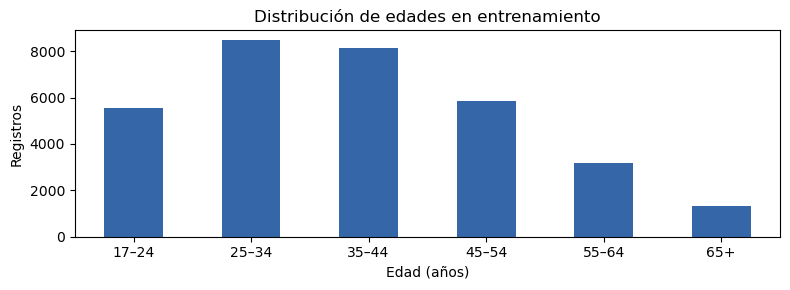

In [25]:
# Grafica la edad agrupada en el conjunto de entrenamiento.
ax = edad_grafico.plot.bar(figsize=(8, 3), color="#3567A8", rot=0)
ax.set(title="Distribución de edades en entrenamiento", xlabel="Edad (años)", ylabel="Registros")
plt.tight_layout()
plt.show()

El intervalo de 25 a 34 años tiene el mayor número de registros. El de 65 años o más tiene menos observaciones, por lo que el gráfico describe una muestra con representación desigual por edad.

### Ingresos por nivel educativo

In [26]:
# Calcula la proporción de la clase positiva por nivel educativo.
educacion_grafico = (train.groupBy("education_num")
    .agg((100 * F.avg("label")).alias("Porcentaje"))
    .orderBy("education_num").toPandas().set_index("education_num")["Porcentaje"])
educacion_grafico.index = educacion_grafico.index.astype(int)

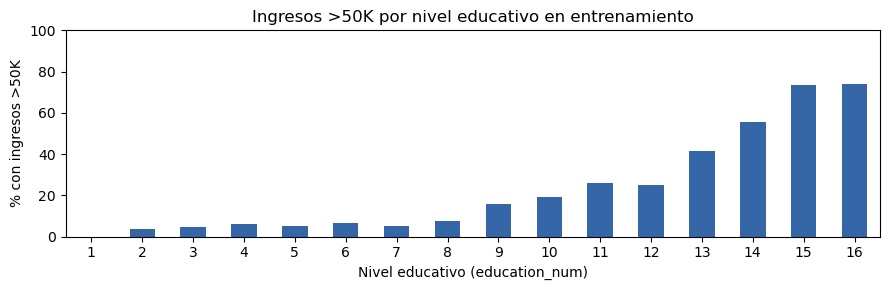

In [27]:
# Grafica el porcentaje >50K por nivel educativo.
ax = educacion_grafico.plot.bar(figsize=(9, 3), color="#3567A8", rot=0)
ax.set(title="Ingresos >50K por nivel educativo en entrenamiento",
       xlabel="Nivel educativo (education_num)", ylabel="% con ingresos >50K", ylim=(0, 100))
plt.tight_layout()
plt.show()

Los niveles educativos más altos muestran en general mayor proporción de ingresos superiores a USD 50.000. El nivel 16 supera el 70 %, mientras que los primeros niveles están por debajo del 10 %. El gráfico describe una asociación en entrenamiento.

### Control después de la limpieza

In [28]:
# Verifica los nulos y cuenta los faltantes convertidos a Desconocido.
def estado_preparado(datos):
    expresiones = [F.count(F.when(F.col(c).isNull(), 1)).alias(f"{c}|Nulo")
                   for c in datos.columns]
    expresiones += [F.count(F.when(F.col(c) == "Desconocido", 1)).alias(f"{c}|Desconocido")
                    for c in categoricas]
    return datos.select(*expresiones).first().asDict()

In [29]:
# Muestra los nulos remanentes por partición.
estado_limpieza = pd.DataFrame({"Entrenamiento": estado_preparado(train),
                                "Prueba": estado_preparado(test)})
display(estado_limpieza.loc[estado_limpieza.index.str.endswith("|Nulo")].sum().to_frame("Nulos"))

,Nulos
Entrenamiento,0
Prueba,0


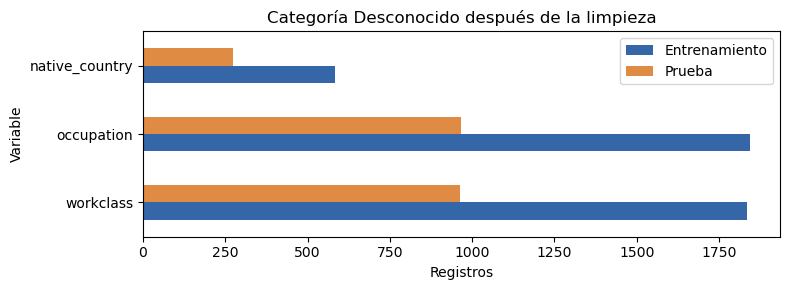

In [30]:
# Visualiza dónde quedaron los faltantes recodificados.
desconocidos = estado_limpieza.loc[estado_limpieza.index.str.endswith("|Desconocido")].copy()
desconocidos = desconocidos.loc[desconocidos.sum(axis=1) > 0]
desconocidos.index = desconocidos.index.str.split("|", regex=False).str[0]
ax = desconocidos.plot.barh(figsize=(8, 3), color=["#3567A8", "#E08B43"])
ax.set(title="Categoría Desconocido después de la limpieza", xlabel="Registros", ylabel="Variable")
plt.tight_layout()
plt.show()

Los conteos de `Desconocido` en las tres variables coinciden con los marcadores `?` originales. El control sobre las tablas preparadas permite comprobar si quedó algún nulo, incluida la etiqueta.

### Edad y jornada laboral por nivel de ingreso

In [31]:
# Resume edad y horas por clase para comparar sus distribuciones.
def frecuencia_clase(variable):
    grupos = train.groupBy(variable, "label").count().toPandas()
    tabla_clases = grupos.pivot(index=variable, columns="label", values="count").fillna(0)
    return tabla_clases.div(tabla_clases.sum(axis=0), axis=1).mul(100).rename(
        columns={0.0: "≤50K", 1.0: ">50K"})

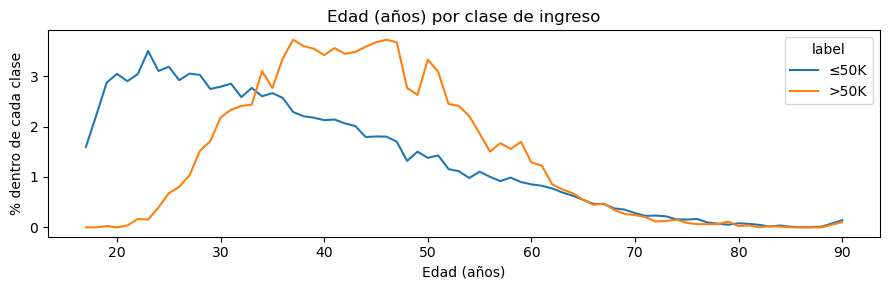

In [32]:
# Compara edad (años) usando porcentajes dentro de cada clase.
ax = frecuencia_clase("age").plot(figsize=(9, 3))
ax.set(title="Edad (años) por clase de ingreso", xlabel="Edad (años)", ylabel="% dentro de cada clase")
plt.tight_layout()
plt.show()

La edad mediana es 34 años en la clase ≤50K y 44 en >50K. Las distribuciones se superponen, así que la edad por sí sola no separa las clases.

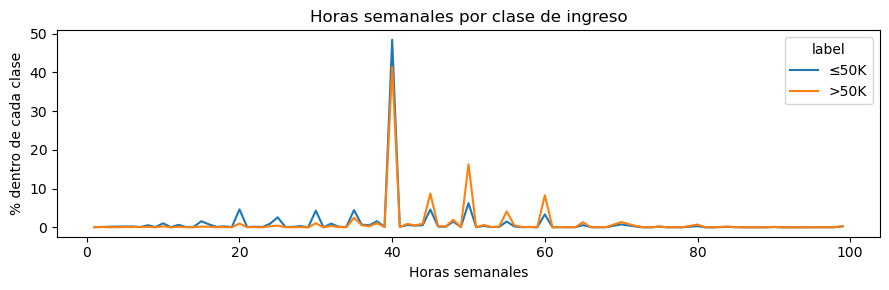

In [33]:
# Compara horas semanales usando porcentajes dentro de cada clase.
ax = frecuencia_clase("hours_per_week").plot(figsize=(9, 3))
ax.set(title="Horas semanales por clase de ingreso", xlabel="Horas semanales", ylabel="% dentro de cada clase")
plt.tight_layout()
plt.show()

Las 40 horas son el valor más frecuente en ambas clases. La proporción en jornadas superiores a 40 horas es mayor en >50K, aunque existen personas con ingresos de ambos grupos que trabajan esas jornadas.

### Ocupación e ingresos

In [34]:
# Calcula cuántos registros y qué proporción supera el umbral por ocupación.
ocupaciones = (train.groupBy("occupation")
    .agg(F.count("*").alias("Registros"), (100 * F.avg("label")).alias("Porcentaje"))
    .orderBy(F.desc("Registros"), "occupation").limit(10).toPandas()
    .set_index("occupation").sort_values("Porcentaje"))

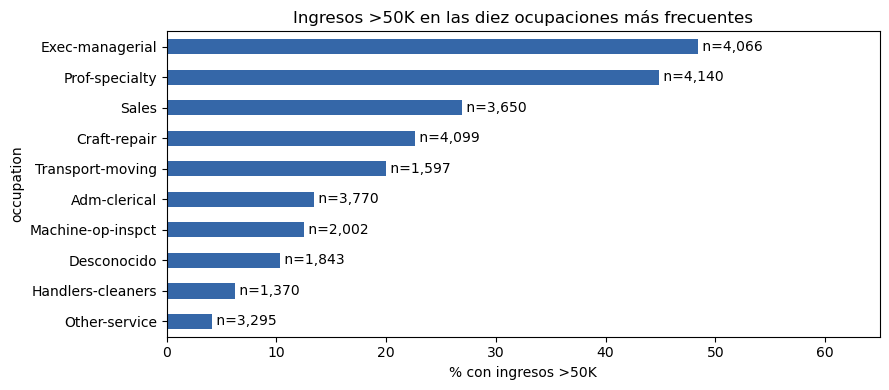

In [35]:
# Dibuja la proporción positiva y anota el tamaño de cada ocupación.
ax = ocupaciones["Porcentaje"].plot.barh(figsize=(9, 4), color="#3567A8")
ax.set(title="Ingresos >50K en las diez ocupaciones más frecuentes", xlabel="% con ingresos >50K", xlim=(0, 65))
for barra, total in zip(ax.patches, ocupaciones["Registros"]):
    ax.annotate(f" n={total:,}", (barra.get_width(), barra.get_y() + barra.get_height()/2), va="center")
plt.tight_layout()
plt.show()

Entre las ocupaciones más frecuentes, `Exec-managerial` y `Prof-specialty` presentan proporciones altas de ingresos >50K. El tamaño al lado de cada barra permite interpretar esos porcentajes según cuántos registros los respaldan.

### Ganancias y pérdidas de capital

In [36]:
# Calcula el porcentaje con ganancia o pérdida de capital distinta de cero.
capital = (train.groupBy("label").agg(
    (100 * F.avg((F.col("capital_gain") > 0).cast("double"))).alias("Ganancia"),
    (100 * F.avg((F.col("capital_loss") > 0).cast("double"))).alias("Pérdida"))
    .orderBy("label").toPandas().set_index("label").rename(index={0.0: "≤50K", 1.0: ">50K"}))

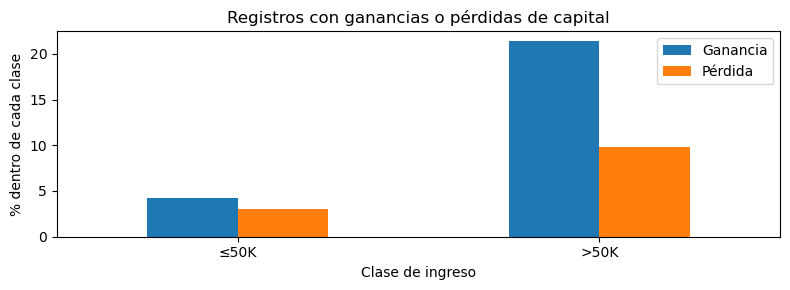

In [37]:
# Compara cuántas observaciones tienen capital distinto de cero por clase.
ax = capital.plot.bar(figsize=(8, 3), rot=0)
ax.set(title="Registros con ganancias o pérdidas de capital", xlabel="Clase de ingreso", ylabel="% dentro de cada clase")
plt.tight_layout()
plt.show()

En ambas clases la mayoría tiene cero en estas variables. Los registros con ganancias de capital son más frecuentes en >50K, lo que muestra una diferencia entre clases que un promedio general ocultaría.

## 5. Modelado con Spark MLlib

Se ajusta el preprocesamiento solo en entrenamiento. StringIndexer identifica las categorías y reserva un índice para valores nuevos. OneHotEncoder evita asignar un orden artificial a las categorías. VectorAssembler reúne todas las características. Los modelos lineales estandarizan internamente durante el ajuste.


| Modelo | Por qué se incluye |
|---|---|
| Regresión logística | Sirve como referencia porque estima una probabilidad de superar el umbral a partir de una combinación lineal de los predictores. |
| Árbol de decisión | Permite explorar reglas no lineales y combinaciones de variables, por ejemplo entre horas trabajadas y nivel educativo. |
| Random Forest | Permite comparar el árbol individual con un promedio de múltiples árboles para reducir la sensibilidad a una sola estructura de decisión. |
| Gradient-Boosted Trees | Evalúa si el ajuste secuencial de árboles mejora la detección de la clase positiva al corregir errores del ensamble. |
| SVM lineal | Compara dos enfoques de clasificación lineal. La SVM optimiza un margen de separación y la regresión logística estima probabilidades. |

In [38]:
# Selecciona predictores y define los nombres de la codificación.
numericas_modelo = [c for c in numericas if c != "fnlwgt"]
categoricas_modelo = [c for c in categoricas if c != "education"]
indices = [c + "_idx" for c in categoricas_modelo]
vectores = [c + "_ohe" for c in categoricas_modelo]

In [39]:
# Configura la codificación categórica y el vector de características.
codificadores = [
    StringIndexer(inputCol=columna, outputCol=indice, handleInvalid="keep")
    for columna, indice in zip(categoricas_modelo, indices)
]
encoder = OneHotEncoder(inputCols=indices, outputCols=vectores, dropLast=False)
ensamblador = VectorAssembler(inputCols=numericas_modelo + vectores, outputCol="features")

In [40]:
# Ajusta el preprocesamiento en entrenamiento y lo aplica a prueba.
preprocesador = Pipeline(stages=codificadores + [encoder, ensamblador]).fit(train)
train_ml = preprocesador.transform(train).select("label", "features").cache()
test_ml = preprocesador.transform(test).select("label", "features").cache()

In [41]:
# Fija la semilla y prepara el registro de modelos.
semilla = 1055
modelos = {}

### Regresión logística

Establece una referencia lineal y estima la probabilidad de superar el umbral.

In [42]:
# Entrena la regresión logística.
estimador = LogisticRegression(maxIter=50, regParam=0.01)
modelos["Regresión logística"] = estimador.fit(train_ml)

### Árbol de decisión

Representa reglas e interacciones entre variables mediante divisiones sucesivas.

In [43]:
# Entrena el árbol de decisión.
estimador = DecisionTreeClassifier(maxDepth=6, seed=semilla)
modelos["Árbol de decisión"] = estimador.fit(train_ml)

### Random Forest

Combina varios árboles para reducir la dependencia de una sola estructura de decisión.

In [44]:
# Entrena Random Forest.
estimador = RandomForestClassifier(numTrees=40, maxDepth=8, seed=semilla)
modelos["Random Forest"] = estimador.fit(train_ml)

26/11/24 11:59:32 WARN DAGScheduler: Broadcasting large task binary with size 1081.2 KiB
                                                                                

### Gradient-Boosted Trees

Ajusta árboles de forma secuencial para corregir errores del ensamble.

In [45]:
# Entrena Gradient-Boosted Trees.
estimador = GBTClassifier(maxIter=25, maxDepth=4, seed=semilla)
modelos["Gradient-Boosted Trees"] = estimador.fit(train_ml)

### SVM lineal

Busca un margen de separación entre clases y ofrece otra referencia lineal.

In [46]:
# Entrena la SVM lineal.
estimador = LinearSVC(maxIter=50, regParam=0.01)
modelos["SVM lineal"] = estimador.fit(train_ml)

## 6. Evaluación

La clase positiva es `>50K`. La precisión indica cuántas alertas positivas fueron correctas y el recall indica cuántos positivos reales se recuperaron. F1 combina ambas. ROC-AUC y PR-AUC usan el puntaje del modelo. La referencia mayoritaria predice la clase más frecuente en entrenamiento y se evalúa en prueba.

In [47]:
# Evita divisiones por cero al evaluar.
def dividir(numerador, denominador):
    return numerador / denominador if denominador else 0.0

In [48]:
# Calcula las métricas y los conteos de la matriz de confusión.
def evaluar_clases(nombre, predicciones):
    conteos = {(int(r.label), int(r.prediction)): r["count"]
               for r in predicciones.groupBy("label", "prediction").count().collect()}
    vn, fp = conteos.get((0, 0), 0), conteos.get((0, 1), 0)
    fn, vp = conteos.get((1, 0), 0), conteos.get((1, 1), 0)
    precision = dividir(vp, vp + fp)
    recall = dividir(vp, vp + fn)
    return {"Modelo": nombre, "Exactitud": dividir(vn + vp, vn + fp + fn + vp),
            "Precisión >50K": precision, "Recall >50K": recall,
            "F1 >50K": dividir(2 * precision * recall, precision + recall),
            "VN": vn, "FP": fp, "FN": fn, "VP": vp}

In [49]:
# Evalúa los cinco modelos con la partición oficial de prueba.
auc_roc = BinaryClassificationEvaluator(metricName="areaUnderROC")
auc_pr = BinaryClassificationEvaluator(metricName="areaUnderPR")
resultados = []
for nombre, modelo in modelos.items():
    predicciones = modelo.transform(test_ml).select("label", "prediction", "rawPrediction").cache()
    try:
        fila = evaluar_clases(nombre, predicciones)
        fila["ROC-AUC"] = auc_roc.evaluate(predicciones)
        fila["PR-AUC"] = auc_pr.evaluate(predicciones)
        resultados.append(fila)
    finally:
        predicciones.unpersist()

In [50]:
# Calcula la referencia de la clase mayoritaria.
mayoritaria = train.groupBy("label").count().orderBy(F.desc("count"), "label").first().label
referencia = evaluar_clases("Clase mayoritaria", test.withColumn("prediction", F.lit(mayoritaria)))

In [51]:
# Ordena y muestra la tabla de resultados.
ranking = pd.DataFrame(resultados).sort_values(["F1 >50K", "PR-AUC"], ascending=False)
tabla = pd.concat([ranking, pd.DataFrame([referencia])], ignore_index=True)
metricas = ["Exactitud", "Precisión >50K", "Recall >50K", "F1 >50K", "ROC-AUC", "PR-AUC"]
display(tabla[["Modelo"] + metricas + ["VN", "FP", "FN", "VP"]].round(4))

,Modelo,Exactitud,Precisión >50K,Recall >50K,F1 >50K,ROC-AUC,PR-AUC,VN,FP,FN,VP
0,SVM lineal,0.8521,0.7327,0.5887,0.6528,0.9014,0.7543,11609,826,1582,2264
1,Gradient-Boosted Trees,0.8573,0.7691,0.5655,0.6518,0.9085,0.7762,11782,653,1671,2175
2,Regresión logística,0.8498,0.7312,0.5757,0.6442,0.9025,0.7506,11621,814,1632,2214
3,Random Forest,0.8450,0.7827,0.4758,0.5918,0.8998,0.7441,11927,508,2016,1830
4,Árbol de decisión,0.8418,0.7745,0.4662,0.5820,0.7491,0.3891,11913,522,2053,1793
5,Clase mayoritaria,0.7638,0.0000,0.0000,0.0000,NaN,NaN,12435,0,3846,0


## 7. Gráficos y análisis de resultados

El primer gráfico muestra la distribución de clases de entrenamiento y prueba. Los dos siguientes comparan las métricas de la clase positiva y el desempeño de ordenamiento por ROC-AUC y PR-AUC. En las matrices de confusión, las filas son las clases reales y las columnas son las predichas.

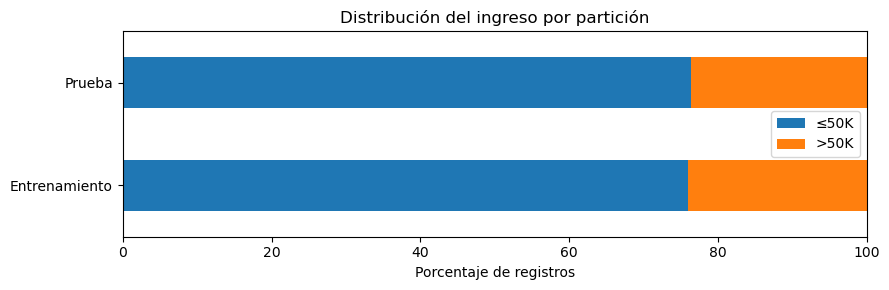

In [52]:
# Compara la proporción de clases de ambas particiones.
distribucion = pd.DataFrame({
    nombre: {int(fila.label): fila["count"]
             for fila in datos.groupBy("label").count().collect()}
    for nombre, datos in [("Entrenamiento", train), ("Prueba", test)]
}).T.rename(columns={0: "≤50K", 1: ">50K"})

ax = distribucion.div(distribucion.sum(axis=1), axis=0).mul(100).plot.barh(
    stacked=True, figsize=(9, 3), title="Distribución del ingreso por partición"
)
ax.set(xlabel="Porcentaje de registros", xlim=(0, 100))
plt.tight_layout()
plt.show()

La clase >50K representa cerca de una cuarta parte de cada partición (24,1 % en entrenamiento y 23,6 % en prueba). La proporción similar permite comparar las particiones y muestra el desbalance.

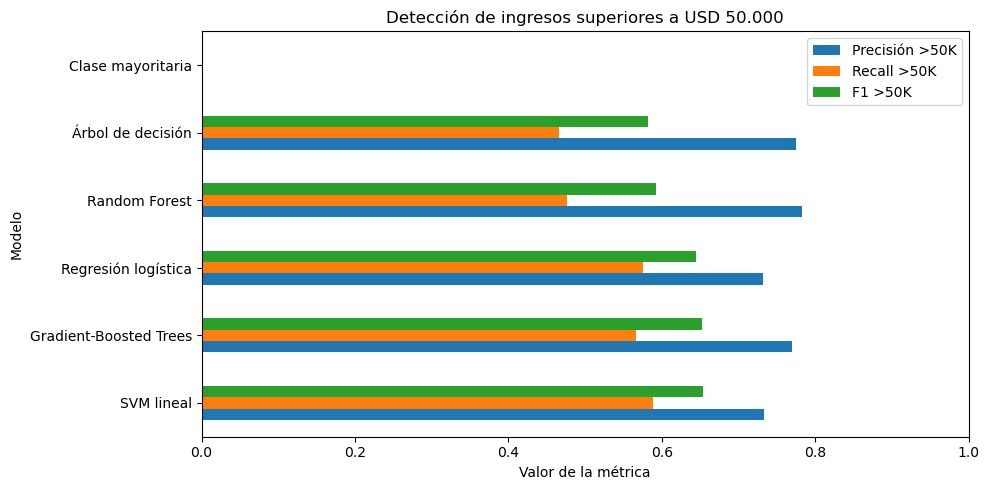

In [53]:
# Compara precisión, recall y F1 para la clase positiva.
ax = tabla.set_index("Modelo")[["Precisión >50K", "Recall >50K", "F1 >50K"]].plot.barh(
    figsize=(10, 5), xlim=(0, 1), title="Detección de ingresos superiores a USD 50.000"
)
ax.set_xlabel("Valor de la métrica")
plt.tight_layout()
plt.show()

La SVM tuvo el mayor recall y F1 para >50K. Random Forest logró la mayor precisión positiva y detectó menos de la mitad de los positivos reales.

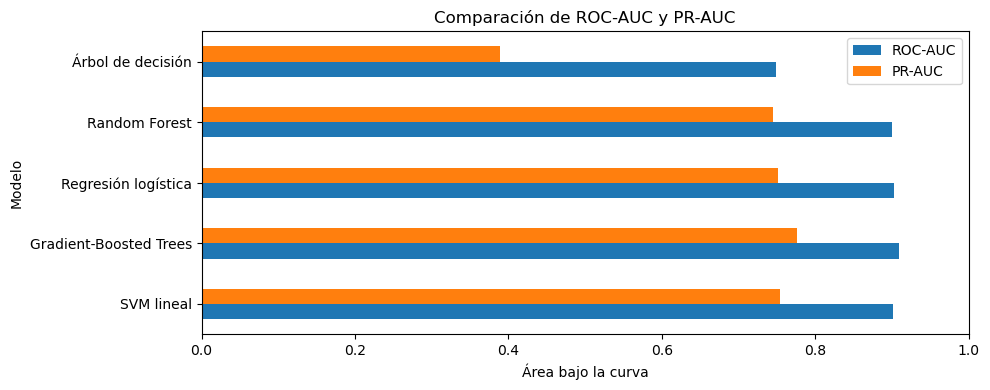

In [54]:
# Compara ROC-AUC y PR-AUC de los cinco modelos.
ax = ranking.set_index("Modelo")[["ROC-AUC", "PR-AUC"]].plot.barh(
    figsize=(10, 4), xlim=(0, 1), title="Comparación de ROC-AUC y PR-AUC"
)
ax.set_xlabel("Área bajo la curva")
plt.tight_layout()
plt.show()

Gradient-Boosted Trees obtuvo la mayor ROC-AUC (0,9085) y PR-AUC (0,7762). Estas métricas resumen el ordenamiento de los casos a través de distintos umbrales.

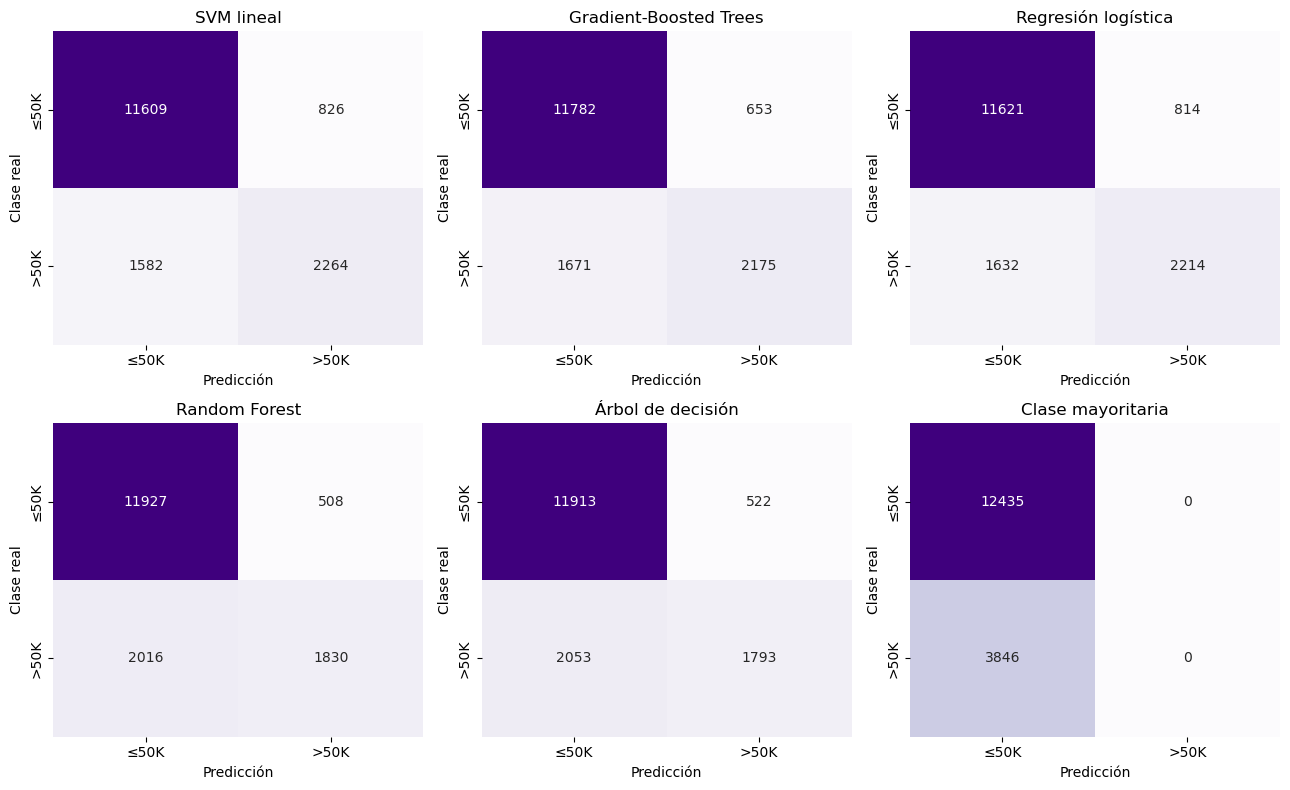

In [66]:
# Reúne las matrices de confusión en una figura.
fig, ejes = plt.subplots(2, 3, figsize=(13, 8))
for eje, (_, fila) in zip(ejes.flat, tabla.iterrows()):
    matriz = [[int(fila["VN"]), int(fila["FP"])], [int(fila["FN"]), int(fila["VP"])]]
    sns.heatmap(matriz, annot=True, fmt="d", cbar=False, cmap="Purples", ax=eje,
                xticklabels=["≤50K", ">50K"], yticklabels=["≤50K", ">50K"])
    eje.set(title=fila["Modelo"], xlabel="Predicción", ylabel="Clase real")
fig.tight_layout()
plt.show()

La referencia mayoritaria omitió todos los positivos. Entre los modelos, la SVM tuvo menos falsos negativos y Random Forest menos falsos positivos.

### Tipos de error y aciertos por clase

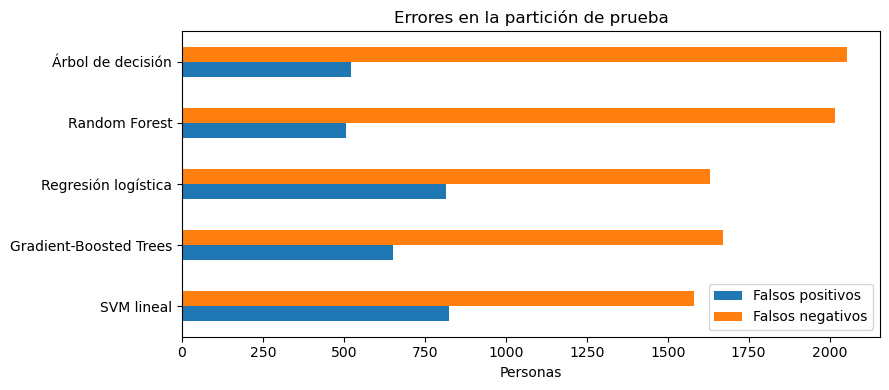

In [56]:
# Compara cuántos falsos positivos y negativos produce cada modelo.
ax = ranking.set_index("Modelo")[["FP", "FN"]].rename(
    columns={"FP": "Falsos positivos", "FN": "Falsos negativos"}).plot.barh(figsize=(9, 4))
ax.set(title="Errores en la partición de prueba", xlabel="Personas", ylabel="")
plt.tight_layout()
plt.show()

El mayor número de errores corresponde a falsos negativos en los cinco modelos. La SVM omitió menos casos >50K (1.582), mientras que Random Forest produjo menos falsos positivos (508).

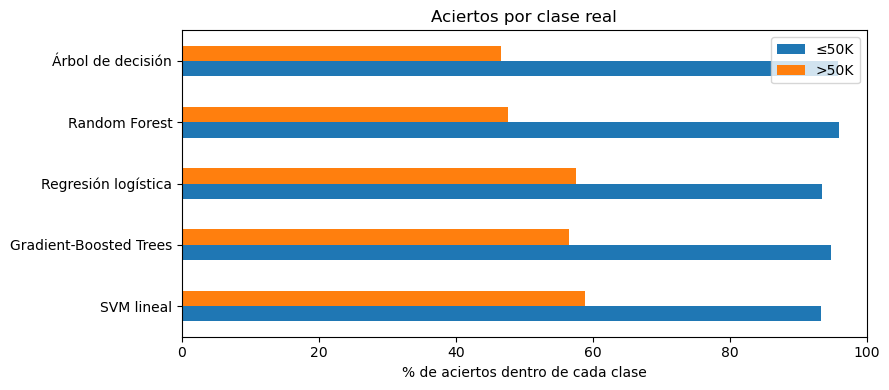

In [57]:
# Compara qué porcentaje de cada clase fue clasificado correctamente.
r = ranking.set_index("Modelo")
aciertos = pd.DataFrame({"≤50K": r["VN"] / (r["VN"] + r["FP"]),
                        ">50K": r["VP"] / (r["VP"] + r["FN"])})
ax = aciertos.mul(100).plot.barh(figsize=(9, 4), xlim=(0, 100))
ax.set(title="Aciertos por clase real", xlabel="% de aciertos dentro de cada clase", ylabel="")
plt.tight_layout()
plt.show()

Todos los modelos acertaron más en la clase ≤50K. La SVM alcanzó el mayor porcentaje de aciertos en >50K (58,87 %), mientras que Random Forest acertó cerca del 96 % en ≤50K. El gráfico muestra qué clase favorece la exactitud global.

### Matriz de confusión por modelo

In [58]:
# Dibuja una matriz independiente con la misma escala para los cinco modelos.
def graficar_matriz(nombre):
    fila = ranking.set_index("Modelo").loc[nombre]
    matriz = [[int(fila["VN"]), int(fila["FP"])],
              [int(fila["FN"]), int(fila["VP"])]]
    fig, ax = plt.subplots(figsize=(5, 3.5))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", vmin=0, vmax=12435,
                cbar=False, xticklabels=["≤50K", ">50K"], yticklabels=["≤50K", ">50K"], ax=ax)
    ax.set(title=nombre, xlabel="Predicción", ylabel="Clase real")
    fig.tight_layout()
    plt.show()

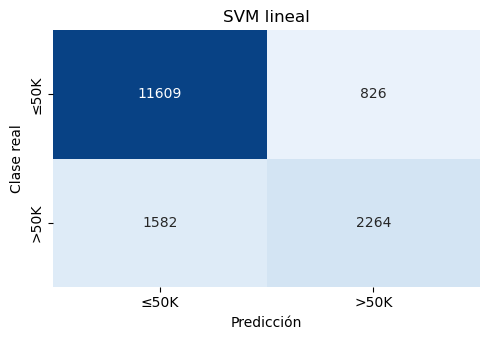

In [59]:
# Muestra los aciertos y errores de SVM lineal.
graficar_matriz("SVM lineal")

Detectó **2.264** casos >50K, la cifra más alta entre los cinco modelos. También tuvo el mayor número de falsos positivos (**826**), lo que ayuda a explicar su mayor recall y su menor precisión frente a Gradient-Boosted Trees.

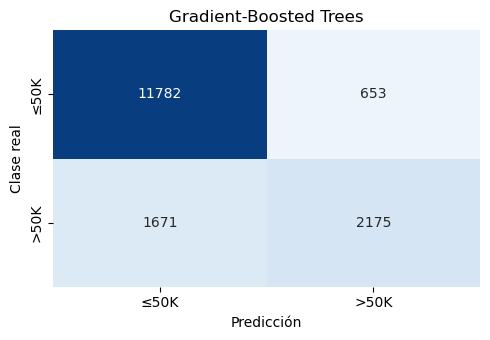

In [60]:
# Muestra los aciertos y errores de Gradient-Boosted Trees.
graficar_matriz("Gradient-Boosted Trees")

Detectó **2.175** casos >50K y produjo **653** falsos positivos. Frente a la SVM, detectó 89 positivos menos y produjo 173 falsos positivos menos.

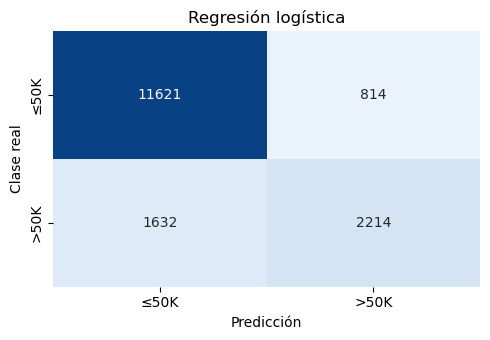

In [61]:
# Muestra los aciertos y errores de Regresión logística.
graficar_matriz("Regresión logística")

Detectó **2.214** casos >50K y omitió **1.632**. Frente a la SVM, detectó 50 casos positivos menos y produjo 12 falsos positivos menos.

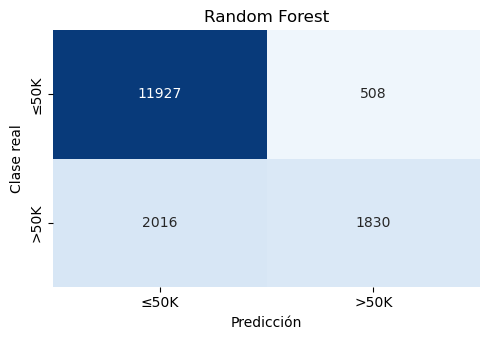

In [62]:
# Muestra los aciertos y errores de Random Forest.
graficar_matriz("Random Forest")

Tuvo **508** falsos positivos, el menor número entre los cinco modelos. También dejó pasar **2.016** casos >50K, lo que muestra el costo de esa mayor precisión en términos de recall.

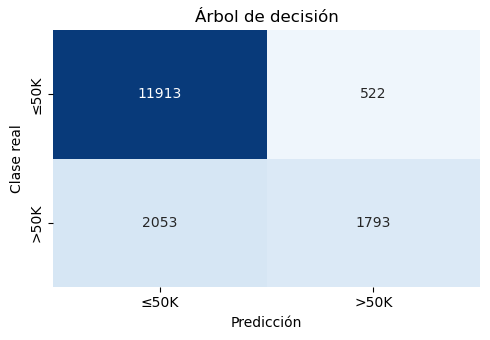

In [63]:
# Muestra los aciertos y errores de Árbol de decisión.
graficar_matriz("Árbol de decisión")

Detectó **1.793** casos >50K y omitió **2.053**. Fue el modelo con menor recall positivo (46,62 %).

### Interpretación de resultados

**Distribución de clases.** En prueba, 3.846 de 16.281 registros (23,6 %) correspondían a ingresos superiores a USD 50.000. Predecir siempre la clase mayoritaria dio 76,38 % de exactitud, pero detectó 0 de los 3.846 casos positivos. Por eso la comparación prioriza el F1 y el recall de la clase positiva.

**Comparación de los cinco modelos.** La SVM lineal obtuvo el mayor F1 positivo (0,6528) y el mayor recall (58,87 %), con una precisión de 73,27 %. Gradient-Boosted Trees quedó muy cerca en F1 (0,6518) y lideró en exactitud (85,73 %), ROC-AUC (0,9085) y PR-AUC (0,7762). La regresión logística obtuvo un F1 de 0,6442. Random Forest alcanzó la mayor precisión positiva (78,27 %), con un recall de 47,58 % y un F1 de 0,5918. El árbol de decisión obtuvo un F1 de 0,5820 y un recall de 46,62 %.

**Matrices de confusión.** La SVM detectó 2.264 positivos reales, omitió 1.582 y produjo 826 falsos positivos. Gradient-Boosted Trees detectó 2.175 positivos, omitió 1.671 y produjo 653 falsos positivos. En esta prueba, la SVM detectó 89 positivos adicionales a cambio de 173 falsos positivos adicionales.

## 8. Conclusiones

1. Se entrenaron cinco clasificadores de PySpark MLlib con datos leídos desde Hadoop HDFS. Los cinco superaron la exactitud de la referencia mayoritaria y detectaron casos de ingresos superiores a USD 50.000.
2. Con los umbrales usados, la SVM lineal mostró el mayor F1 y recall para la clase positiva. Gradient-Boosted Trees obtuvo la mayor exactitud y las mayores áreas bajo las curvas ROC y precisión-recall. La diferencia de F1 entre ambos fue de 0,0010 en esta partición, por lo que el orden observado debe interpretarse con cautela.
3. La elección depende del costo de los errores. En la prueba, la SVM omitió menos casos positivos y Gradient-Boosted Trees produjo menos falsos positivos. Incluso la SVM dejó sin detectar el 41,13 % de los casos positivos.
4. El conjunto es histórico y las métricas agregadas no permiten evaluar posibles diferencias de desempeño entre grupos demográficos. Para ajustar hiperparámetros o el umbral de decisión, se requiere una partición de validación y una prueba independiente para la evaluación final.

In [64]:
# Libera los DataFrames guardados en memoria.
for datos in (train_ml, test_ml, train, test):
    datos.unpersist()

## 9. Lo que aprendí

En este taller aprendí a pasar de los archivos originales a un conjunto de datos listo para entrenar en PySpark. Al cargar los archivos desde HDFS, tuve que revisar el orden de las columnas, verificar los tipos de datos y reconocer que un valor faltante también puede aparecer como ?. Me ayudó comparar los conteos antes y después de la limpieza para comprobar que había conservado los registros.

También entendí por qué la codificación de las variables categóricas se ajusta con los datos de entrenamiento y luego se aplica a los de prueba. También aprendí a revisar la distribución de las clases antes de entrenar. Como había menos casos de ingresos superiores a USD 50.000, entendí que la exactitud por sí sola podía ocultar cuántos de esos casos quedaban sin detectar. Al revisar el recall y las matrices de confusión, pude identificar qué tipo de error cometía cada modelo.



### Cierre de la sesión de Spark

Al finalizar el taller, se detiene la sesión de esta aplicación para liberar los recursos de Spark.

In [65]:
# Detiene la sesión Spark del taller.
sparkGarcia.stop()